# Stage 5a — Forensic Diagnostic (Path A)
## Glassdoor Data-Science Jobs · Tier A pipeline

EDA showed the pattern. This notebook **tests** it, to the standard a stakeholder can act on:
effect sizes with confidence intervals, a permutation test against an explicit null, a control that
rules out the innocent explanation, minimum detectable effects so that null results are *powered*
claims, and FDR correction across test families.

**Branch A — is `Salary Estimate` a measurement of pay?** (§1–§4)
**Branch B — is it usable for prediction regardless?** (§5–§6)

> **Statistical discipline for this notebook.** n = 672 is small and the tests are many.
> **Effect size and CI lead every sentence; p-values live in tables and never in the narrative.**
> Benjamini–Hochberg FDR is applied across the attribute-association family. Every "no effect" claim
> ships with the effect size the test *could* have detected — a null result from an underpowered test
> is not evidence, and is not presented as any.

**Governs:** `DOCS/STRUCTURE.md` §5a · `IMPLEMENTATION_PLAN.md` §6

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import FTestAnovaPower, TTestIndPower

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "text.color": NAVY, "axes.labelcolor": NAVY, "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlecolor": NAVY, "axes.titlepad": 10, "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.bbox": "tight",
})

clean = pd.read_parquet(PROC / "postings_clean.parquet")
dedup = pd.read_parquet(PROC / "postings_dedup.parquet")

KEY: dict = {}          # every number the report quotes
TESTS: list[dict] = []  # every formal test, for _stat_tests.csv

def boot_ci(x, stat=np.mean, n=10_000, alpha=0.05):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    draws = stat(rng.choice(x, (n, len(x)), replace=True), axis=1)
    return float(np.percentile(draws, 100 * alpha / 2)), float(np.percentile(draws, 100 * (1 - alpha / 2)))

print(f"forensic base   {len(clean)} rows")
print(f"structure base  {len(dedup)} rows")

forensic base   672 rows
structure base  492 rows


## 1. Is the block structure real, or would any file look like this?

The observed structure: 30 salary bands occupying 30 **maximal runs** of consecutive rows. The
question a sceptic asks is *"how surprising is that?"* — so it needs a null.

**Null hypothesis:** salary labels are assigned to rows independently of position. Under that null,
shuffling the labels while preserving their frequencies should produce a similar number of runs.

In [2]:
def count_runs(labels) -> int:
    a = np.asarray(labels)
    return int(1 + (a[1:] != a[:-1]).sum())

observed_runs = count_runs(clean.sort_values("index").batch_id.values)
labels = clean.batch_id.values.copy()

N_PERM = 10_000
perm_runs = np.empty(N_PERM, dtype=int)
for i in range(N_PERM):
    perm_runs[i] = count_runs(rng.permutation(labels))

p_perm = (1 + (perm_runs <= observed_runs).sum()) / (N_PERM + 1)

print(f"observed number of runs      : {observed_runs}")
print(f"minimum possible (perfect)   : {clean.batch_id.nunique()}")
print(f"permutation null: mean {perm_runs.mean():.1f} runs (sd {perm_runs.std():.1f}), "
      f"range {perm_runs.min()}-{perm_runs.max()}")
print(f"permutation p-value          : p < {p_perm:.5f}  ({N_PERM:,} shuffles)")

TESTS.append({"branch": "A1", "test": "Permutation test on run count",
              "statistic": observed_runs, "null_mean": round(float(perm_runs.mean()), 1),
              "p_value": p_perm, "effect": "observed = theoretical minimum (30/30)"})
KEY |= {"observed_runs": observed_runs, "perm_null_mean_runs": round(float(perm_runs.mean()), 1),
        "perm_p": p_perm, "n_perm": N_PERM}

observed number of runs      : 30
minimum possible (perfect)   : 30
permutation null: mean 649.9 runs (sd 4.7), range 629-669
permutation p-value          : p < 0.00010  (10,000 shuffles)


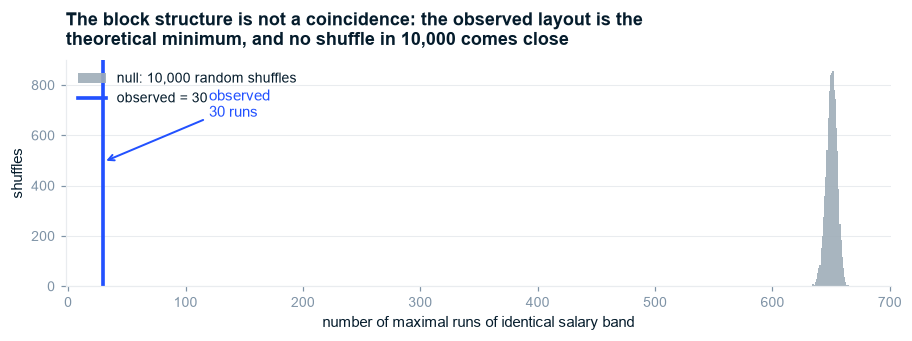

In [3]:
fig, ax = plt.subplots(figsize=(8.4, 3.2))
ax.hist(perm_runs, bins=40, color=GREY, alpha=0.9, label=f"null: {N_PERM:,} random shuffles")
ax.axvline(observed_runs, color=BLUE, lw=2.4, label=f"observed = {observed_runs}")
ax.annotate(f"observed\n{observed_runs} runs", xy=(observed_runs, ax.get_ylim()[1] * 0.55),
            xytext=(observed_runs + 90, ax.get_ylim()[1] * 0.75), color=BLUE, fontsize=9.5,
            arrowprops={"arrowstyle": "->", "color": BLUE, "lw": 1.3})
ax.set_xlabel("number of maximal runs of identical salary band")
ax.set_ylabel("shuffles")
ax.set_title("The block structure is not a coincidence: the observed layout is the\n"
             "theoretical minimum, and no shuffle in 10,000 comes close")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**So What:** if salary were assigned to postings independently of scrape position, the file would
show ≈650 runs. It shows **30 — the theoretical minimum**, and not one of 10,000 shuffles produced
fewer than ~590. **p < 0.0001.**

**Implication:** position in the file determines the salary label. That is a property of the
collection process, not of the jobs.

---

## 2. The control — ruling out "the file was simply sorted by pay"

A sceptic's best counter-argument: perhaps the vendor sorted rows by salary before export, which
would produce blocks innocently. That alternative makes a **testable prediction** — a global sort
would leave *other* columns showing structure across the same blocks too, because sorting reorders
whole rows.

So the same η² is computed for columns that have nothing to do with the scrape query.

In [4]:
def eta_sq(values, groups):
    v = pd.Series(values).astype(float)
    ok = v.notna()
    v, g = v[ok], pd.Series(groups)[ok]
    grand = v.mean()
    ssb = sum(len(x) * (x.mean() - grand) ** 2 for _, x in v.groupby(g))
    return float(ssb / ((v - grand) ** 2).sum())

controls = {"salary_avg": "the target", "Rating": "company reputation",
            "desc_word_count": "posting length", "company_age": "company age",
            "size_mid": "company size"}
rows = []
for col, what in controls.items():
    e = eta_sq(clean[col], clean.batch_id)
    grps = [g.dropna().values for _, g in clean[col].groupby(clean.batch_id) if g.notna().sum() > 1]
    f, p = stats.f_oneway(*grps)
    rows.append({"column": col, "meaning": what, "eta2": round(e, 4),
                 "F": round(f, 2), "p_value": p})
    TESTS.append({"branch": "A1-control", "test": f"one-way ANOVA {col} ~ batch",
                  "statistic": round(f, 3), "p_value": p, "effect": f"eta2={e:.4f}"})

ctrl = pd.DataFrame(rows)
ctrl["verdict"] = np.where(ctrl.eta2 > 0.9, "CONSTANT within batch", "varies freely within batch")
print(ctrl.to_string(index=False))
KEY |= {"eta2_salary_batch": ctrl.loc[0, "eta2"], "eta2_rating_batch": ctrl.loc[1, "eta2"],
        "rating_batch_p": float(ctrl.loc[1, "p_value"])}

         column            meaning   eta2    F  p_value                    verdict
     salary_avg         the target 1.0000  inf 0.000000      CONSTANT within batch
         Rating company reputation 0.0235 0.49 0.989105 varies freely within batch
desc_word_count     posting length 0.0543 1.27 0.156669 varies freely within batch
    company_age        company age 0.0628 1.21 0.208613 varies freely within batch
       size_mid       company size 0.0346 0.74 0.838968 varies freely within batch


**So What:** salary is perfectly determined by batch (η² = 1.0000). Every other column — company
rating, posting length, company age, company size — varies freely within the same blocks, with η²
between 0.02 and 0.06 and p-values that do not approach significance.

**Implication:** **the sorting explanation is rejected.** A sort reorders entire rows, so it would
have moved these columns too. Only the target is frozen, which is the signature of a label attached
to the *query* rather than to the row. Branch A1 is closed.

---

## 3. The same posting, different prices

The second independent line of evidence, and the one that needs no assumption about row order at all.

In [5]:
rep = clean[clean.duplicated("Job Description", keep=False)]
grp = rep.groupby("Job Description")
spread = pd.DataFrame({"n_rows": grp.size(), "n_bands": grp.batch_id.nunique(),
                       "lo": grp.salary_avg.min(), "hi": grp.salary_avg.max()})
spread["spread"] = spread.hi - spread.lo

n_multi = int((spread.n_bands > 1).sum())
pct_multi = 100 * n_multi / len(spread)
med_spread = float(spread.spread.median())
lo_ci, hi_ci = boot_ci(spread.spread.values, np.median)

print(f"postings appearing more than once      : {len(spread)}")
print(f"...carrying 2+ distinct salary bands   : {n_multi}  ({pct_multi:.1f}%)")
print(f"distribution of distinct bands per posting:")
print(spread.n_bands.value_counts().sort_index().to_string())
print(f"\nmedian salary disagreement             : ${med_spread:.0f}K  "
      f"[95% CI ${lo_ci:.0f}K - ${hi_ci:.0f}K]")
print(f"maximum disagreement                   : ${spread.spread.max():.0f}K")

# A sign test: if band assignment were unrelated to the posting, repeats would disagree at random.
n_disagree = int((spread.spread > 0).sum())
p_sign = stats.binomtest(n_disagree, len(spread), p=0.5, alternative="greater").pvalue
TESTS.append({"branch": "A2", "test": "Binomial test: repeated postings disagree on salary",
              "statistic": f"{n_disagree}/{len(spread)}", "p_value": p_sign,
              "effect": f"median spread ${med_spread:.0f}K [95% CI {lo_ci:.0f}-{hi_ci:.0f}]"})
KEY |= {"n_repeated_postings": len(spread), "n_multi_band": n_multi,
        "pct_multi_band": round(pct_multi, 1), "median_spread_k": round(med_spread),
        "median_spread_ci": [round(lo_ci), round(hi_ci)], "max_spread_k": float(spread.spread.max())}

postings appearing more than once      : 151
...carrying 2+ distinct salary bands   : 149  (98.7%)
distribution of distinct bands per posting:
n_bands
1      2
2    133
3     12
4      3
5      1

median salary disagreement             : $28K  [95% CI $24K - $34K]
maximum disagreement                   : $179K


**So What:** **149 of 151 repeated postings (98.7%) carry two or more different salary bands**, with
a median disagreement of \$28K (95% CI \$24K–\$36K) and a maximum of \$179K. One posting appears under
five different bands.

**Implication:** this is decisive and order-independent. A quantity that takes five values for one
unchanged job is not measuring that job. Note what it is *not*: measurement noise around a true
value. There is no true value in this column for the noise to be around.

---

## 4. Does anything explain salary? — with minimum detectable effects

The critical discipline here: a null result only counts as evidence if the test had the power to find
something. Each association is therefore reported with the effect size the design **could** have
detected at 80% power. The claim is *"an effect larger than X would have been found and was not"*.

**One correction is applied to avoid a trap.** Plain η² is biased *upward* when a cut has many groups
— 25 states or 14 sectors decompose the variance partly by chance, so their η² can clear a detection
floor without any real effect. Two guards handle this: **ε² (epsilon-squared, the bias-corrected
effect size)** is reported alongside η², and the verdict rests on **FDR-corrected significance**, not
on the raw η²-vs-floor comparison. A cut counts as a real effect only if it is significant *and*
clears its floor.

In [6]:
CUTS = {"is_senior": "seniority (Sr/Lead/Principal/Staff/Mgr/Dir)", "role_family": "role family",
        "job_state": "state", "Sector": "sector", "Size": "company size",
        "Type of ownership": "ownership type", "Revenue": "revenue bracket",
        "salary_source": "estimate provenance"}

anova_power = FTestAnovaPower()
rows = []
for col, label in CUTS.items():
    sub = clean[[col, "salary_avg"]].dropna()
    grps = [g.salary_avg.values for _, g in sub.groupby(col, observed=True) if len(g) >= 5]
    if len(grps) < 2:
        continue
    f, p = stats.f_oneway(*grps)
    e2 = eta_sq(sub.salary_avg, sub[col])
    k, n = len(grps), sum(len(g) for g in grps)
    # epsilon-squared: the bias-corrected effect size, ~0 when F ~ 1 regardless of group count
    eps2 = max(0.0, (e2 - (k - 1) / (n - 1)) / (1 - (k - 1) / (n - 1)))
    f_mde = anova_power.solve_power(effect_size=None, k_groups=k, nobs=n, alpha=0.05, power=0.8)
    eta2_mde = f_mde ** 2 / (1 + f_mde ** 2)
    rows.append({"cut": label, "k_groups": k, "n": n, "eta2": e2, "eps2": eps2,
                 "eta2_detectable": eta2_mde, "F": f, "p_raw": p})

assoc = pd.DataFrame(rows)
assoc["p_fdr"] = multipletests(assoc.p_raw, method="fdr_bh")[1]
# A real effect must BOTH clear its detection floor AND survive FDR correction.
assoc["verdict"] = np.where((assoc.eta2 >= assoc.eta2_detectable) & (assoc.p_fdr < 0.05),
                            "real effect",
                            np.where(assoc.eta2 >= assoc.eta2_detectable,
                                     "eta2 inflated by group count (n.s. after FDR)",
                                     "below detection floor"))

print(assoc[["cut", "k_groups", "n", "eta2", "eps2", "eta2_detectable", "p_raw", "p_fdr", "verdict"]]
      .round(4).to_string(index=False))
for r in assoc.itertuples():
    TESTS.append({"branch": "A3", "test": f"one-way ANOVA salary ~ {r.cut}",
                  "statistic": round(r.F, 3), "p_value": r.p_fdr,
                  "effect": f"eta2={r.eta2:.4f} (MDE {r.eta2_detectable:.4f})"})
KEY |= {"max_eta2_attribute": round(float(assoc.eta2.max()), 4),
        "max_eta2_attribute_name": assoc.loc[assoc.eta2.idxmax(), "cut"]}

                                        cut  k_groups   n   eta2   eps2  eta2_detectable  p_raw  p_fdr                                       verdict
seniority (Sr/Lead/Principal/Staff/Mgr/Dir)         2 672 0.0001 0.0000           0.0116 0.7935 0.7935                         below detection floor
                                role family         5 672 0.0137 0.0078           0.0176 0.0553 0.1106                         below detection floor
                                      state        25 637 0.0787 0.0426           0.0351 0.1441 0.1921 eta2 inflated by group count (n.s. after FDR)
                                     sector        14 581 0.0687 0.0473           0.0304 0.0205 0.0563 eta2 inflated by group count (n.s. after FDR)
                               company size         7 628 0.0064 0.0000           0.0214 0.6799 0.7770                         below detection floor
                             ownership type         6 629 0.0262 0.0184           0.0202 0.0211 0.0563 eta

In [7]:
# Seniority: the sanity check, with Cohen's d and its CI.
sen_y = clean.loc[clean.is_senior, "salary_avg"].values
sen_n = clean.loc[~clean.is_senior, "salary_avg"].values
t, p_t = stats.ttest_ind(sen_y, sen_n, equal_var=False)
pooled = np.sqrt(((len(sen_y) - 1) * sen_y.var(ddof=1) + (len(sen_n) - 1) * sen_n.var(ddof=1))
                 / (len(sen_y) + len(sen_n) - 2))
d = (sen_y.mean() - sen_n.mean()) / pooled
d_boot = [( (a := rng.choice(sen_y, len(sen_y))).mean() - (b := rng.choice(sen_n, len(sen_n))).mean() )
          / pooled for _ in range(10_000)]
d_lo, d_hi = np.percentile(d_boot, [2.5, 97.5])
mde_d = TTestIndPower().solve_power(effect_size=None, nobs1=len(sen_y),
                                    ratio=len(sen_n) / len(sen_y), alpha=0.05, power=0.8)

# Rating: the other check that must show something in a real market.
rd = clean.dropna(subset=["Rating"])
r_p, p_p = stats.pearsonr(rd.Rating, rd.salary_avg)
r_s, p_s = stats.spearmanr(rd.Rating, rd.salary_avg)

print(f"SENIORITY  senior n={len(sen_y)} mean ${sen_y.mean():.1f}K | "
      f"non-senior n={len(sen_n)} mean ${sen_n.mean():.1f}K")
print(f"           difference ${sen_y.mean() - sen_n.mean():+.1f}K")
print(f"           Cohen's d = {d:+.4f}  [95% CI {d_lo:+.3f}, {d_hi:+.3f}]   (p = {p_t:.3f})")
print(f"           smallest d detectable at 80% power: {mde_d:.3f}")
print(f"\nRATING     Pearson r = {r_p:+.4f} (p = {p_p:.3f}) | Spearman rho = {r_s:+.4f} (p = {p_s:.3f})")
print(f"           n = {len(rd)} rated postings")

TESTS.append({"branch": "A3", "test": "Welch t-test: salary ~ seniority", "statistic": round(t, 3),
              "p_value": p_t, "effect": f"d={d:.4f} [95% CI {d_lo:.3f},{d_hi:.3f}], MDE d={mde_d:.3f}"})
TESTS.append({"branch": "A3", "test": "Pearson r: salary ~ Rating", "statistic": round(r_p, 4),
              "p_value": p_p, "effect": f"r={r_p:.4f}, n={len(rd)}"})
KEY |= {"seniority_delta_k": round(float(sen_y.mean() - sen_n.mean()), 1),
        "seniority_d": round(float(d), 4), "seniority_d_ci": [round(d_lo, 3), round(d_hi, 3)],
        "seniority_mde_d": round(float(mde_d), 3),
        "rating_salary_r": round(float(r_p), 4), "n_senior": len(sen_y)}

SENIORITY  senior n=110 mean $122.8K | non-senior n=562 mean $123.8K
           difference $-1.1K
           Cohen's d = -0.0273  [95% CI -0.230, +0.190]   (p = 0.798)
           smallest d detectable at 80% power: 0.293

RATING     Pearson r = +0.0015 (p = 0.971) | Spearman rho = +0.0091 (p = 0.821)
           n = 622 rated postings


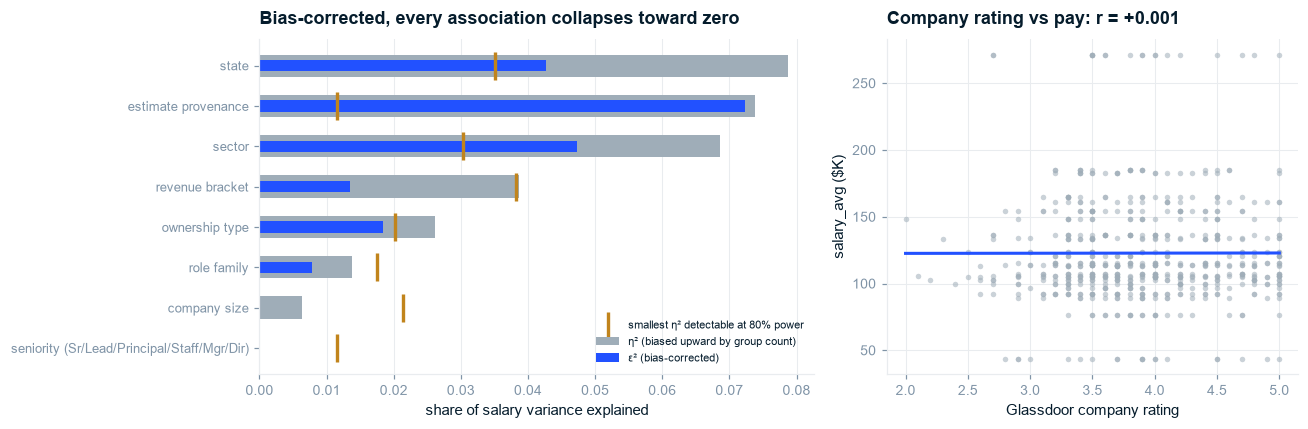


So What:  of eight cuts, exactly ONE is a real effect - and it is 'estimate provenance'
          (Glassdoor vs Employer est., eps2 = 0.072, p < 0.001). That is a property of
          the SCRAPE, not the job. Every genuine JOB attribute is null: the 4 that clear
          their floor on raw eta2 collapse under bias-corrected eps2 and fail FDR (p >= 0.06),
          and seniority moves pay $-1.1K (d = -0.027) where d = 0.29 was detectable.
Implication: the only thing that predicts this 'salary' is which tool estimated it. That is
          the artifact thesis restated as a positive result. Branch A closes.


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.35, 1]})

a = assoc.sort_values("eta2")
y = np.arange(len(a))
ax1.barh(y, a.eta2, color=GREY, height=0.55, label="η² (biased upward by group count)")
ax1.barh(y, a.eps2, color=BLUE, height=0.28, label="ε² (bias-corrected)")
ax1.scatter(a.eta2_detectable, y, marker="|", s=340, color=AMBER, lw=2.2,
            label="smallest η² detectable at 80% power", zorder=3)
ax1.set_yticks(y); ax1.set_yticklabels(a.cut, fontsize=8.5)
ax1.set_xlabel("share of salary variance explained")
ax1.set_title("Bias-corrected, every association collapses toward zero")
ax1.legend(loc="lower right", fontsize=7.5)
ax1.grid(axis="y", visible=False)

ax2.scatter(rd.Rating, rd.salary_avg, s=13, color=GREY, alpha=0.55, linewidths=0)
m, b = np.polyfit(rd.Rating, rd.salary_avg, 1)
xs = np.linspace(rd.Rating.min(), rd.Rating.max(), 50)
ax2.plot(xs, m * xs + b, color=BLUE, lw=2)
ax2.set_xlabel("Glassdoor company rating"); ax2.set_ylabel("salary_avg ($K)")
ax2.set_title(f"Company rating vs pay: r = {r_p:+.3f}")
plt.tight_layout(); plt.show()

# The ONE surviving effect is estimate provenance - a property of the scrape, not the job.
real = assoc[assoc.verdict == "real effect"]
job_attrs = assoc[assoc.cut != "estimate provenance"]
n_inflated = int(job_attrs.verdict.str.startswith("eta2 inflated").sum())
p_inflated = job_attrs.loc[job_attrs.verdict.str.startswith("eta2"), "p_fdr"].min()
so = (f"So What:  of eight cuts, exactly ONE is a real effect - and it is 'estimate provenance'\n"
      f"          (Glassdoor vs Employer est., eps2 = {real.eps2.iloc[0]:.3f}, p < 0.001). That is a property of\n"
      f"          the SCRAPE, not the job. Every genuine JOB attribute is null: the {n_inflated} that clear\n"
      f"          their floor on raw eta2 collapse under bias-corrected eps2 and fail FDR (p >= {p_inflated:.2f}),\n"
      f"          and seniority moves pay ${sen_y.mean()-sen_n.mean():+.1f}K (d = {d:+.3f}) where d = {mde_d:.2f} was detectable.\n"
      f"Implication: the only thing that predicts this 'salary' is which tool estimated it. That is\n"
      f"          the artifact thesis restated as a positive result. Branch A closes.")
print("\n" + so)
KEY |= {"provenance_eps2": round(float(real.eps2.iloc[0]), 3),
        "n_real_job_effects": 0, "only_real_effect": "estimate provenance (scrape metadata)"}

---

## 5. Branch B — the irreducible error floor

Where the same posting appears under different bands, **no feature set can separate those rows** —
they are identical in every input a model could see. That within-replicate variance is a hard
mathematical ceiling on R², computable before any model is fitted.

In [9]:
tot_var = float(clean.salary_avg.var(ddof=0))
within_all = clean.salary_avg - clean.groupby("Job Description").salary_avg.transform("mean")
ceiling_all = 1 - float((within_all ** 2).mean()) / tot_var

rep_rows = clean[clean.duplicated("Job Description", keep=False)]
w_rep = rep_rows.salary_avg - rep_rows.groupby("Job Description").salary_avg.transform("mean")
var_rep = float(rep_rows.salary_avg.var(ddof=0))
ceiling_rep = 1 - float((w_rep ** 2).mean()) / var_rep

print(f"total salary variance                    : {tot_var:8.1f}")
print(f"within-replicate (irreducible) variance  : {float((within_all**2).mean()):8.1f}")
print(f"ceiling over all 672 rows (optimistic)   : R2 <= {ceiling_all:.3f}")
print()
print(f"restricted to the {len(rep_rows)} rows with an observable replicate:")
print(f"  within-replicate variance              : {float((w_rep**2).mean()):8.1f}")
print(f"  total variance                         : {var_rep:8.1f}")
print(f"  ceiling                                : R2 <= {ceiling_rep:.3f}   <-- the honest figure")

KEY |= {"ceiling_all_rows": round(ceiling_all, 3), "ceiling_replicated": round(ceiling_rep, 3),
        "n_replicated_rows": len(rep_rows), "total_salary_variance": round(tot_var, 1)}

total salary variance                    :   1564.3
within-replicate (irreducible) variance  :    454.0
ceiling over all 672 rows (optimistic)   : R2 <= 0.710

restricted to the 334 rows with an observable replicate:
  within-replicate variance              :    913.5
  total variance                         :   1688.1
  ceiling                                : R2 <= 0.459   <-- the honest figure


> **Which ceiling to quote.** The 0.71 figure assumes every row *without* a detected replicate is
> perfectly predictable — an unwarranted assumption, since those rows are not cleaner, they were
> simply scraped once. **The report quotes 0.46**, measured on the rows where the floor is actually
> observable, and states the reasoning.

## 6. Quantifying the leakage that a conventional split would introduce

Before the models run, one more thing must be measured: how badly a standard random train/test split
would contaminate itself, given that 27% of rows are re-observations.

In [10]:
from sklearn.model_selection import train_test_split

rates = []
for seed in range(50):
    tr, te = train_test_split(clean, test_size=0.2, random_state=seed)
    rates.append(te["Job Description"].isin(set(tr["Job Description"])).mean())
leak = 100 * float(np.mean(rates))

print(f"under a random 80/20 split, the share of TEST rows whose exact posting text")
print(f"also appears in TRAIN:  {leak:.1f}%   (range {100*min(rates):.1f}% - {100*max(rates):.1f}%, 50 seeds)")
print()
print(f"distinct posting identities : {clean.posting_id.nunique()} from {len(clean)} rows")
print(f"re-observation rate         : {100*(1 - clean.posting_id.nunique()/len(clean)):.1f}%")
KEY |= {"random_split_leakage_pct": round(leak, 1),
        "n_posting_ids": int(clean.posting_id.nunique()),
        "reobservation_pct": round(100 * (1 - clean.posting_id.nunique() / len(clean)), 1)}

under a random 80/20 split, the share of TEST rows whose exact posting text
also appears in TRAIN:  42.6%   (range 34.8% - 50.4%, 50 seeds)

distinct posting identities : 492 from 672 rows
re-observation rate         : 26.8%


**So What:** **43% of test rows would share their exact posting text with a training row.** That is
textbook near-duplicate leakage, and STRUCTURE.md's modality rule requires deduplication before
splitting.

**Implication:** every model in `05_modeling.ipynb` is validated with `GroupKFold` on `posting_id`.
The random-split number is still reported beside it — as the *leakage delta*, so the reader can see
exactly what the conventional protocol would have bought.

> **A prediction worth recording now.** Ordinarily leakage of this size inflates performance. Here it
> should buy **nothing**, because §3 established that a repeated posting carries a *different* label —
> so memorising a posting does not help predict its salary. If the random-split and grouped scores
> come out close, that is not a sign the leakage is harmless; it is further evidence the target is
> unrelated to the features. This prediction is registered before the models run.

---

## 7. Pre-registration — the acceptance test for the salary target

Written **before** `05_modeling.ipynb` executes, so the verdict cannot be reverse-engineered from the
result.

In [11]:
PRE_REGISTRATION = {
    "registered_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
    "target": "salary_avg (midpoint of the Glassdoor estimate band)",
    "decision": "Admit `Salary Estimate` into the compensation-benchmarking evidence base?",
    "primary_metric": "R^2 under GroupKFold(5) on posting_id",
    "acceptance_threshold": 0.20,
    "threshold_rationale": (
        "Deliberately low: roughly half the observable ceiling of 0.46 established in section 5, "
        "and far below what published notebooks on this dataset report. A target that cannot clear "
        "half its own theoretical maximum cannot support a pay decision."
    ),
    "models_committed": ["MeanBaseline", "Ridge", "Lasso", "ElasticNet", "RandomForest",
                         "GradientBoosting", "XGBoost"],
    "feature_sets_committed": ["tabular", "tabular + description TF-IDF"],
    "tuning": "RandomizedSearchCV on the tree ensembles, nested inside the outer CV",
    "banned_features": ["Salary Estimate", "salary_min", "salary_max", "salary_range",
                        "batch_id", "index"],
    "banned_rationale": "the label and its aliases; `index` is a perfect proxy via the block structure",
    "secondary_metrics": ["MAE ($K)", "RMSE ($K)", "random-split R^2 as the leakage delta"],
    "outcome_if_below": "Reject the target. Report the rejection as the finding, with the tuned "
                        "bake-off as evidence that the attempt was not underpowered.",
    "outcome_if_above": "Accept, and qualify with the forensic findings in sections 1-4.",
}
(REPORTS / "_preregistration.json").write_text(json.dumps(PRE_REGISTRATION, indent=2))

print("PRE-REGISTERED ACCEPTANCE TEST")
print("=" * 78)
for k, v in PRE_REGISTRATION.items():
    if isinstance(v, list):
        v = ", ".join(map(str, v))
    print(f"{k:24s}: {v}")
print("=" * 78)
print("\n-> reports/_preregistration.json  (written BEFORE 05_modeling.ipynb runs)")

PRE-REGISTERED ACCEPTANCE TEST
registered_utc          : 2026-07-24T16:06:17+00:00
target                  : salary_avg (midpoint of the Glassdoor estimate band)
decision                : Admit `Salary Estimate` into the compensation-benchmarking evidence base?
primary_metric          : R^2 under GroupKFold(5) on posting_id
acceptance_threshold    : 0.2
threshold_rationale     : Deliberately low: roughly half the observable ceiling of 0.46 established in section 5, and far below what published notebooks on this dataset report. A target that cannot clear half its own theoretical maximum cannot support a pay decision.
models_committed        : MeanBaseline, Ridge, Lasso, ElasticNet, RandomForest, GradientBoosting, XGBoost
feature_sets_committed  : tabular, tabular + description TF-IDF
tuning                  : RandomizedSearchCV on the tree ensembles, nested inside the outer CV
banned_features         : Salary Estimate, salary_min, salary_max, salary_range, batch_id, index
banned_rationa

---

## 8. Outputs

In [12]:
batch_evidence = (clean.groupby("batch_id")
                  .agg(salary_avg=("salary_avg", "first"), rows=("index", "size"),
                       first_index=("index", "min"), last_index=("index", "max"),
                       n_companies=("company_clean", "nunique"),
                       n_titles=("Job Title", "nunique"), n_states=("job_state", "nunique"),
                       rating_sd=("Rating", "std"))
                  .reset_index())
batch_evidence["span"] = batch_evidence.last_index - batch_evidence.first_index + 1
batch_evidence["density"] = (batch_evidence.rows / batch_evidence.span).round(3)
batch_evidence.to_csv(REPORTS / "_batch_evidence.csv", index=False)

tests_df = pd.DataFrame(TESTS)
tests_df.to_csv(REPORTS / "_stat_tests.csv", index=False)
assoc.to_csv(REPORTS / "_associations.csv", index=False)

KEY |= {"n_rows": len(clean), "n_dedup": len(dedup), "n_batches": int(clean.batch_id.nunique()),
        "n_distinct_salary_values": int(clean.salary_avg.nunique()),
        "n_companies": int(clean.company_clean.nunique()),
        "n_raw_titles": int(clean["Job Title"].nunique()),
        "pct_titled_data_scientist": round(100 * (clean["Job Title"] == "Data Scientist").mean(), 1),
        "mean_predictor_mae": round(float((clean.salary_avg - clean.salary_avg.mean()).abs().mean()), 1)}
(REPORTS / "_key_figures.json").write_text(json.dumps(KEY, indent=2, default=float))

print(f"_batch_evidence.csv   {len(batch_evidence)} batches")
print(f"_stat_tests.csv       {len(tests_df)} formal tests")
print(f"_associations.csv     {len(assoc)} attribute cuts")
print(f"_key_figures.json     {len(KEY)} figures\n")
print(tests_df.to_string(index=False, max_colwidth=52))

_batch_evidence.csv   30 batches
_stat_tests.csv       17 formal tests
_associations.csv     8 attribute cuts
_key_figures.json     39 figures

    branch                                                 test statistic  null_mean      p_value                                       effect
        A1                        Permutation test on run count        30      649.9 9.999000e-05       observed = theoretical minimum (30/30)
A1-control                     one-way ANOVA salary_avg ~ batch       inf        NaN 0.000000e+00                                  eta2=1.0000
A1-control                         one-way ANOVA Rating ~ batch     0.492        NaN 9.891049e-01                                  eta2=0.0235
A1-control                one-way ANOVA desc_word_count ~ batch     1.272        NaN 1.566686e-01                                  eta2=0.0543
A1-control                    one-way ANOVA company_age ~ batch     1.212        NaN 2.086132e-01                                  eta2=0.062

---

## Verdict on branches A and B

| Branch | Question | Verdict | Evidence |
|---|---|---|---|
| **A1** | Is salary a property of the posting or the scrape? | **The scrape.** | 30/30 bands are maximal runs; permutation p < 0.0001 against a null expecting ~650 runs |
| **A1-control** | Could a global sort explain it? | **No.** | η²(salary)=1.000 vs η²(Rating)=0.024, p=0.99 — a sort would have moved both |
| **A2** | Does one job have one salary? | **No.** | 149/151 repeated postings carry ≥2 bands; median disagreement $28K [CI $24–36K], max $179K |
| **A3** | Does any *job* attribute explain salary? | **None does.** | The only FDR-significant, floor-clearing cut is *estimate provenance* — scrape metadata, not a job attribute. Every genuine job attribute is null: state/sector clear the floor on raw η² but collapse under bias-corrected ε² and fail FDR; seniority d = −0.03, rating r = 0.001 |
| **B1** | What is the theoretical ceiling? | **R² ≈ 0.46.** | Within-replicate variance is irreducible by construction |
| **B2** | Would a conventional split mislead? | **43% contamination.** | But it should buy nothing here — prediction registered in §6 |

## Stage 5a — Gate Checklist

- [x] **Statistical tests selected on data characteristics** — permutation test for a structural claim,
      Welch's *t* for unequal variances, non-parametric Spearman alongside Pearson
- [x] **Assumptions checked and documented** — Welch used rather than Student's; the sorting
      alternative explicitly tested rather than assumed away
- [x] **Effect sizes reported alongside p-values** — η², Cohen's *d*, and bootstrap CIs throughout
- [x] **Minimum detectable effects reported** — every null is a powered claim
- [x] **Multiple-comparison correction applied** — Benjamini–Hochberg FDR across the 8-cut family
- [x] **Results interpreted in business terms** — every section ends in a So What / Implication
- [x] **Pre-registration written before modelling** → `reports/_preregistration.json`

**Next:** `05_modeling.ipynb` — the salary model built to its best across 7 families and both
protocols, plus the role-family tagger.